# **1. Import Libraries**





In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# **2. Load Dataset**

In [2]:
df = pd.read_csv('/content/Student_scores.csv')

# **3. Basic Data Inspection**

In [3]:
df.shape

(30641, 15)

In [4]:
df.head()

,Unnamed: 0,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,0,female,NaN,bachelor's degree,standard,none,married,regularly,yes,3.0,school_bus,< 5,71,71,74
1,1,female,group C,some college,standard,NaN,married,sometimes,yes,0.0,NaN,5 - 10,69,90,88
2,2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91
3,3,male,group A,associate's degree,free/reduced,none,married,never,no,1.0,NaN,5 - 10,45,56,42
4,4,male,group C,some college,standard,none,married,sometimes,yes,0.0,school_bus,5 - 10,76,78,75


In [5]:
df.columns

Index(['Unnamed: 0', 'Gender', 'EthnicGroup', 'ParentEduc', 'LunchType',
       'TestPrep', 'ParentMaritalStatus', 'PracticeSport', 'IsFirstChild',
       'NrSiblings', 'TransportMeans', 'WklyStudyHours', 'MathScore',
       'ReadingScore', 'WritingScore'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30641 entries, 0 to 30640
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           30641 non-null  int64  
 1   Gender               30641 non-null  object 
 2   EthnicGroup          28801 non-null  object 
 3   ParentEduc           28796 non-null  object 
 4   LunchType            30641 non-null  object 
 5   TestPrep             28811 non-null  object 
 6   ParentMaritalStatus  29451 non-null  object 
 7   PracticeSport        30010 non-null  object 
 8   IsFirstChild         29737 non-null  object 
 9   NrSiblings           29069 non-null  float64
 10  TransportMeans       27507 non-null  object 
 11  WklyStudyHours       29686 non-null  object 
 12  MathScore            30641 non-null  int64  
 13  ReadingScore         30641 non-null  int64  
 14  WritingScore         30641 non-null  int64  
dtypes: float64(1), int64(4), object(10)


In [7]:
df.isnull().sum()

,0
Unnamed: 0,0
Gender,0
EthnicGroup,1840
ParentEduc,1845
LunchType,0
TestPrep,1830
ParentMaritalStatus,1190
PracticeSport,631
IsFirstChild,904
NrSiblings,1572


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,Unnamed: 0,NrSiblings,MathScore,ReadingScore,WritingScore
count,30641.000000,29069.000000,30641.000000,30641.000000,30641.000000
mean,499.556607,2.145894,66.558402,69.377533,68.418622
std,288.747894,1.458242,15.361616,14.758952,15.443525
min,0.000000,0.000000,0.000000,10.000000,4.000000
25%,249.000000,1.000000,56.000000,59.000000,58.000000
50%,500.000000,2.000000,67.000000,70.000000,69.000000
75%,750.000000,3.000000,78.000000,80.000000,79.000000
max,999.000000,7.000000,100.000000,100.000000,100.000000


In [10]:
df.nunique()

,0
Unnamed: 0,1000
Gender,2
EthnicGroup,5
ParentEduc,6
LunchType,2
TestPrep,2
ParentMaritalStatus,4
PracticeSport,3
IsFirstChild,2
NrSiblings,8


In [11]:
df['Gender'].unique()

array(['female', 'male'], dtype=object)

In [12]:
df['Gender'].value_counts()

,count
Gender,
female,15424
male,15217


In [13]:
df['LunchType'].value_counts()

,count
LunchType,
standard,19905
free/reduced,10736


In [14]:
df['Unnamed: 0'].value_counts().head(10)

,count
Unnamed: 0,
828,31
0,31
1,31
2,31
802,31
4,31
681,31
660,31
636,31


# **4. Data Cleaning**

In [15]:
# remove unnecessary column
df = df.drop(columns=['Unnamed: 0'])

In [16]:
df.shape

(30641, 14)

Handle Missing Values

In [17]:
# check missing values
df.isnull().sum()

,0
Gender,0
EthnicGroup,1840
ParentEduc,1845
LunchType,0
TestPrep,1830
ParentMaritalStatus,1190
PracticeSport,631
IsFirstChild,904
NrSiblings,1572
TransportMeans,3134


In [18]:
(df.isnull().sum()/len(df) * 100).round(2)

,0
Gender,0.00
EthnicGroup,6.01
ParentEduc,6.02
LunchType,0.00
TestPrep,5.97
ParentMaritalStatus,3.88
PracticeSport,2.06
IsFirstChild,2.95
NrSiblings,5.13
TransportMeans,10.23


In [ ]:
# fill missng categorical values

In [19]:
df['EthnicGroup'] = df['EthnicGroup'].fillna('Unknown')

In [20]:
df['EthnicGroup']

,EthnicGroup
0,Unknown
1,group C
2,group B
3,group A
4,group C
...,...
30636,group D
30637,group E
30638,Unknown
30639,group D


In [21]:
categorical_columns = [
    'ParentEduc',
    'TestPrep',
    'ParentMaritalStatus',
    'PracticeSport',
    'IsFirstChild',
    'TransportMeans',
    'WklyStudyHours'

]

In [23]:
df[categorical_columns]  = df[categorical_columns].fillna('Unknown')

In [24]:
df.isnull().sum()

,0
Gender,0
EthnicGroup,0
ParentEduc,0
LunchType,0
TestPrep,0
ParentMaritalStatus,0
PracticeSport,0
IsFirstChild,0
NrSiblings,1572
TransportMeans,0


In [25]:
df['NrSiblings'].median()

2.0

In [26]:
# fil missing NrSiblings with median
df['NrSiblings'] = df['NrSiblings'].fillna(2)

In [27]:
# verify missing values
df.isnull().sum()

,0
Gender,0
EthnicGroup,0
ParentEduc,0
LunchType,0
TestPrep,0
ParentMaritalStatus,0
PracticeSport,0
IsFirstChild,0
NrSiblings,0
TransportMeans,0


Check Data Type

In [28]:
df.dtypes

,0
Gender,object
EthnicGroup,object
ParentEduc,object
LunchType,object
TestPrep,object
ParentMaritalStatus,object
PracticeSport,object
IsFirstChild,object
NrSiblings,float64
TransportMeans,object


In [29]:
# check invalid values
df[['MathScore','ReadingScore','WritingScore']].describe()

,MathScore,ReadingScore,WritingScore
count,30641.000000,30641.000000,30641.000000
mean,66.558402,69.377533,68.418622
std,15.361616,14.758952,15.443525
min,0.000000,10.000000,4.000000
25%,56.000000,59.000000,58.000000
50%,67.000000,70.000000,69.000000
75%,78.000000,80.000000,79.000000
max,100.000000,100.000000,100.000000


In [30]:
df.isnull().sum().sum()

np.int64(0)

# **5. Exploratory Data Analysis (EDA)**

In [31]:
# Average Score Analysis
df[['MathScore','ReadingScore','WritingScore']].mean()

,0
MathScore,66.558402
ReadingScore,69.377533
WritingScore,68.418622


**Test Preparation and Student Performance**


*   Question: How does test preparation relate to student's average
scores?



In [32]:
df.groupby('TestPrep')[['MathScore','ReadingScore','WritingScore']].mean()

,MathScore,ReadingScore,WritingScore
TestPrep,,,
Unknown,66.887978,69.655738,68.500000
completed,69.546660,73.732998,74.703265
none,64.948770,67.051071,65.092756


Finding: Students who completed test preparation have higher average scores than students who did not complete it.

**Parent Education vs Student Performance**



*   Question: How does parent's education relate to student's average scores?



In [33]:
gb = df.groupby('ParentEduc')[['MathScore','ReadingScore','WritingScore']].mean()

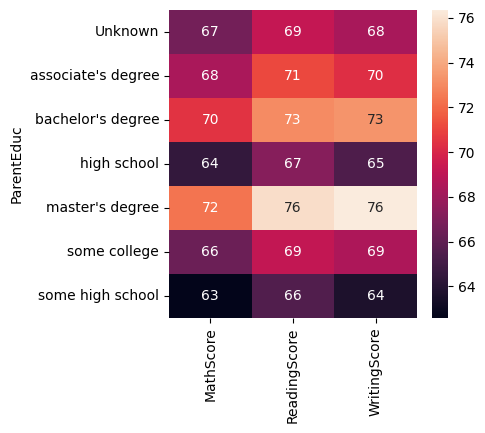

In [34]:
plt.figure(figsize = (4,4))
sns.heatmap(gb,annot=True)
plt.show()

In [35]:
# from the above chart we have concluded that the education of the parents have a good impact

**Highest Scoring Students**

*   Question: Which students have the highest overall scores?



In [36]:
df['AverageScore'] = df[['MathScore','ReadingScore','WritingScore']].mean(axis=1) # axis=1 -> row wise
df.sort_values('AverageScore',ascending=False).head(10)

,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore,AverageScore
30605,female,group E,master's degree,standard,Unknown,married,sometimes,no,2.0,school_bus,5 - 10,100,100,100,100.0
30060,female,group D,bachelor's degree,standard,completed,married,regularly,no,1.0,school_bus,5 - 10,100,100,100,100.0
3460,male,group E,bachelor's degree,free/reduced,completed,divorced,sometimes,yes,0.0,school_bus,> 10,100,100,100,100.0
2683,male,group D,associate's degree,standard,completed,married,regularly,no,1.0,Unknown,> 10,100,100,100,100.0
23353,male,group E,associate's degree,standard,completed,married,sometimes,no,3.0,private,> 10,100,100,100,100.0
432,female,group E,bachelor's degree,standard,none,married,regularly,Unknown,2.0,school_bus,Unknown,100,100,100,100.0
26527,male,group E,bachelor's degree,standard,completed,married,regularly,yes,1.0,school_bus,> 10,100,100,100,100.0
4935,female,group E,master's degree,standard,completed,divorced,regularly,yes,2.0,private,> 10,100,100,100,100.0
2983,male,group D,master's degree,standard,completed,married,sometimes,no,2.0,school_bus,5 - 10,100,100,100,100.0
981,female,group E,high school,standard,completed,divorced,regularly,yes,1.0,private,5 - 10,100,100,100,100.0


 Finding: The table shows the 10 students with the highest overall average scores.





**Score Relationship Visualization**

* Question: Is there a relationship between Math scores and Reading scores?  






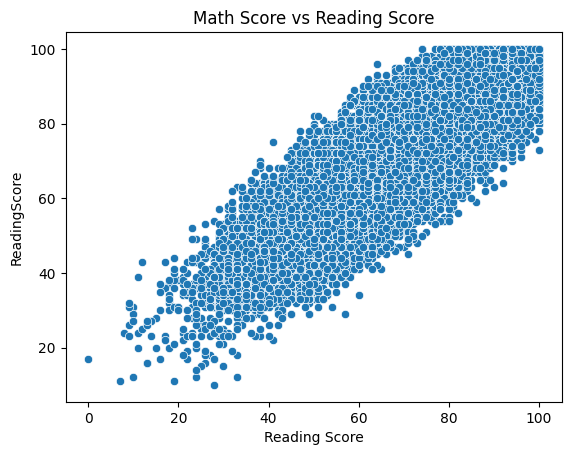

In [37]:
sns.scatterplot(data=df,x='MathScore',y='ReadingScore')
plt.title('Math Score vs Reading Score')
plt.xlabel('Math Score')
plt.xlabel('Reading Score')
plt.show()

 Finding: The scatter plot shows a positive relationship between Math and Reading

# **6. Data Visualization**

**Average Score by Subject**


*   Question: How do the average scores compare across Math, Reading, and Writing?



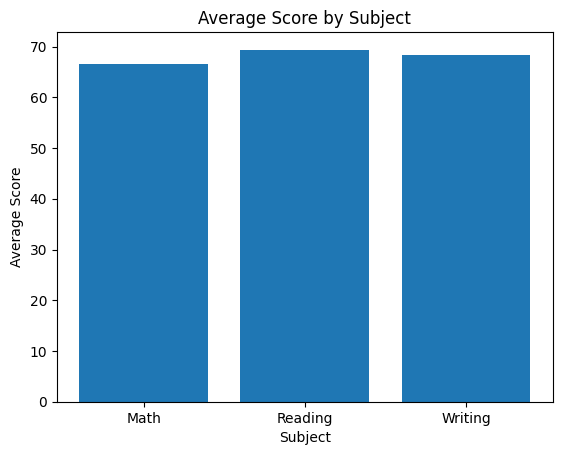

In [38]:
subjects = ['Math', 'Reading', 'Writing']
averages = [
    df['MathScore'].mean(),
    df['ReadingScore'].mean(),
    df['WritingScore'].mean()
]

plt.bar(subjects, averages)

plt.title('Average Score by Subject')
plt.xlabel('Subject')
plt.ylabel('Average Score')

plt.show()

Finding: Reading has the highest average score, followed by Writing and Math.

**Student Count by Gender**


*   Question: How are students distributed by gender?



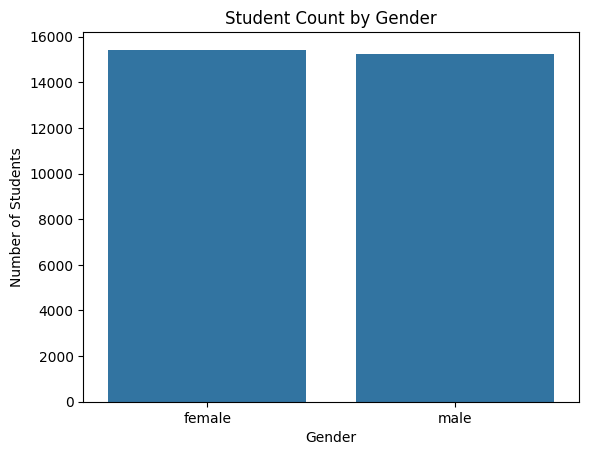

In [39]:
sns.countplot(data=df,x='Gender')
plt.title('Student Count by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Students')
plt.show()

Finding: The number of female students is slightly higher than the number of male students.


**Students by Parents' Education Level**


*   Question: How are students distributed across different parent's education levels?



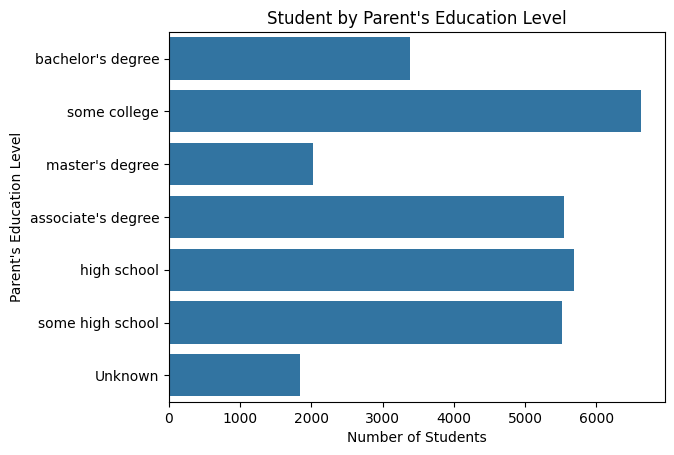

In [40]:
sns.countplot(data=df,y='ParentEduc')
plt.title("Student by Parent's Education Level")
plt.xlabel('Number of Students')
plt.ylabel("Parent's Education Level")
plt.show()

Finding: Most students have parents with some college education. Among the known education levels, master's degree has the lowest number of students.

**Practice Sport and Student Performance**



*   Question: How does practicing sports relate to student's Math scores?



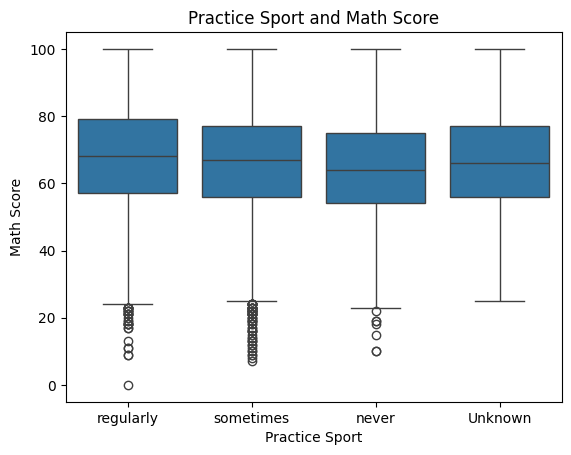

In [41]:
sns.boxplot(data=df,x='PracticeSport',y='MathScore')
plt.title("Practice Sport and Math Score")
plt.xlabel("Practice Sport")
plt.ylabel("Math Score")
plt.show()

Finding: Students who practice sports regularly generally have higher Math scores than students who practice sports sometimes or never.

**Math Score Distribution**


*   Question:How are student's Math scores distributed?



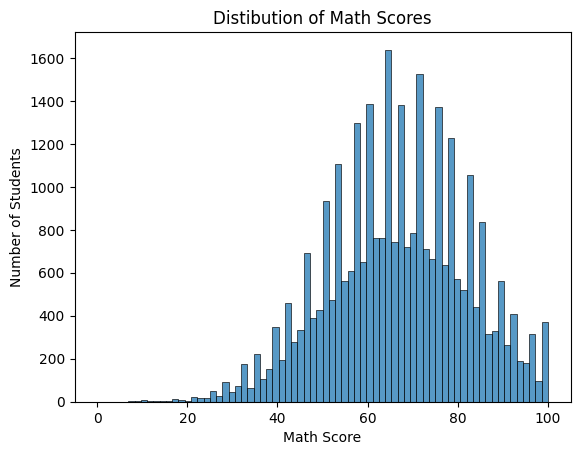

In [42]:
sns.histplot(data=df, x='MathScore')
plt.title('Distibution of Math Scores')
plt.xlabel('Math Score')
plt.ylabel('Number of Students')
plt.show()

Question: Boxplot Of Subject Scores


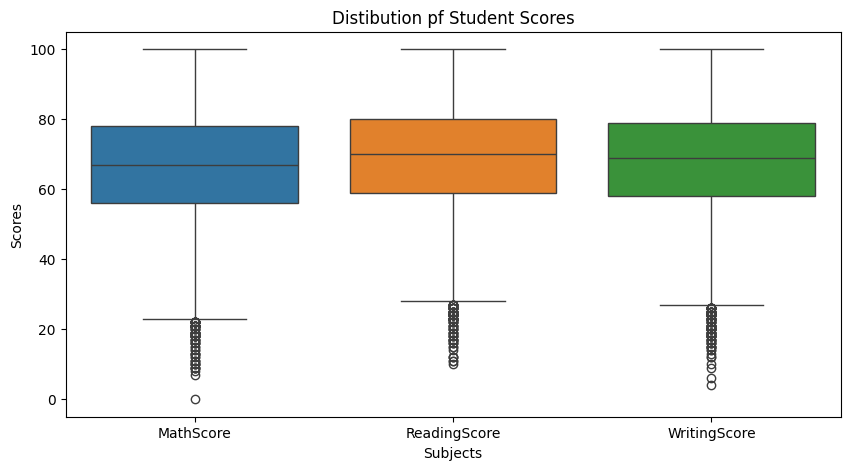

In [52]:
plt.figure(figsize=(10, 5))
sns,sns.boxplot(data=df[['MathScore','ReadingScore','WritingScore']])
plt.title('Distibution pf Student Scores')
plt.xlabel('Subjects')
plt.ylabel('Scores')

plt.show()

Question: Ethnic Group Distribution

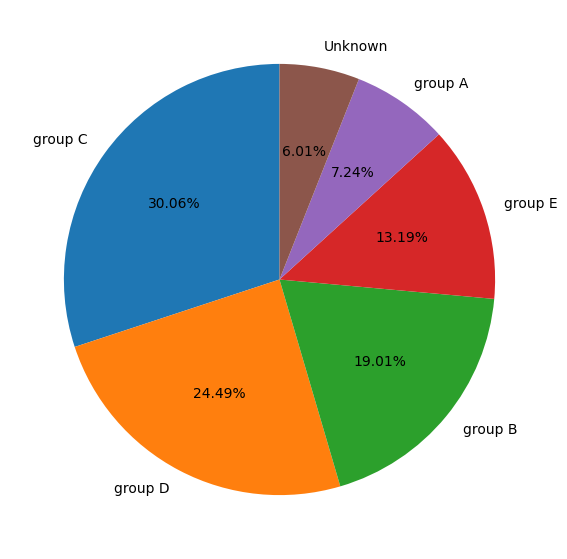

In [71]:
group_counts = df['EthnicGroup'].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(group_counts,
labels=group_counts.index,
autopct='%1.2f%%',
startangle=90)


plt.show()

  Question: Student Count by Ethnic Group
  

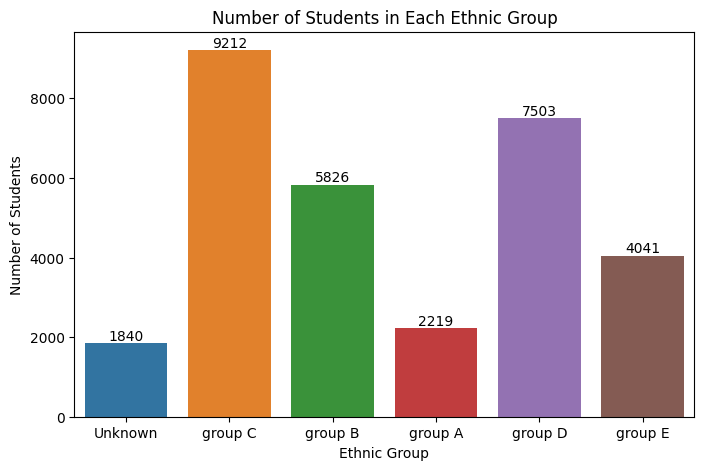

In [82]:
plt.figure(figsize=(8,5))
ax=sns.countplot(data=df,x='EthnicGroup',hue='EthnicGroup')
plt.title('Number of Students in Each Ethnic Group')
plt.xlabel('Ethnic Group')
plt.ylabel('Number of Students')

for container in ax.containers:
  ax.bar_label(container)

plt.show()

# 7. Insights


In [85]:
df.groupby('TestPrep')['MathScore'].mean()

,MathScore
TestPrep,
Unknown,66.887978
completed,69.546660
none,64.948770


Insight:

Students who completed test preparation had higher average scores in all three subjects. The largest difference was in Writing.






In [87]:
df.groupby('TestPrep')[['MathScore','ReadingScore','WritingScore']].mean()

,MathScore,ReadingScore,WritingScore
TestPrep,,,
Unknown,66.887978,69.655738,68.500000
completed,69.546660,73.732998,74.703265
none,64.948770,67.051071,65.092756


Insight:

Among students who completed test preparation, Writing had the highest average score (74.70), while Math had the lowest (69.55).


In [88]:
df.groupby('ParentEduc')[['MathScore','ReadingScore','WritingScore']].mean()

,MathScore,ReadingScore,WritingScore
ParentEduc,,,
Unknown,66.645528,69.225474,68.295935
associate's degree,68.365586,71.124324,70.299099
bachelor's degree,70.466627,73.062020,73.331069
high school,64.435731,67.213997,65.421136
master's degree,72.336134,75.832921,76.356896
some college,66.390472,69.179708,68.501432
some high school,62.584013,65.510785,63.632409


Insight:

Students whose parents had a master's degree showed higher average scores than those whose parents had a high school education.